# Light Sensor Data Analysis ? Regression & Classification

**Dataset:** `data.txt` ? readings from an LDR (light dependent resistor) sensor.

Each line in `data.txt` looks like this:

```
ldr Value:6120.34 voltage:4.71 time:5001
```

| Column | Meaning |
|---|---|
| `ldr_Value` | LDR resistance reading in ohms |
| `voltage` | Voltage reading from the sensor |
| `time` | Timestamp of the reading |
| `brightness` | Resistance-based category: High Brightness, Brightness, or Dark |

With the circuit shown, more light lowers LDR resistance. The three categories are derived from the valid data's resistance terciles: lower resistance means High Brightness, middle resistance means Brightness, and higher resistance means Dark. These are dataset-derived labels, not lux-meter ground truth.

**Plan of this notebook:**
1. Explore and validate the sensor log
2. Predict `ldr_Value` from voltage using a time-ordered holdout
3. Add resistance-based brightness labels and train a classifier on regression predictions
4. Save the regression and classification models separately


## 1. Imports

Install analysis dependencies once from the project root with `python -m pip install -r analysis-requirements.txt`.

In [27]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

%matplotlib inline
plt.style.use("seaborn-v0_8-darkgrid")

## 2. Load the Data

In [28]:
import re

data = []
pattern = re.compile(r"ldr Value:([\d.]+) voltage:([\d.]+) time:([\d.]+)")

with open(Path("data.txt"), "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        m = pattern.match(line)
        if not m:
            continue
        data.append({
            "ldr_Value": float(m.group(1)),
            "voltage": float(m.group(2)),
            "time": float(m.group(3)),
        })

df = pd.DataFrame(data, columns=["ldr_Value", "voltage", "time"])

In [29]:
df.head()

,ldr_Value,voltage,time
0,6120.34,4.71,5001.0
1,6120.34,4.71,10002.0
2,3752.53,4.81,15003.0
3,4069.17,4.80,20004.0
4,1086.96,4.94,25007.0


In [30]:
print("Shape of the dataset:", df.shape)
print("\nData types:\n", df.dtypes)
df.describe()

Shape of the dataset: (2599, 3)

Data types:
 ldr_Value    float64
voltage      float64
time         float64
dtype: object


,ldr_Value,voltage,time
count,2599.000000,2599.000000,2599.000000
mean,17979.298142,4.449962,129795.410927
std,37712.351946,0.729500,75230.680448
min,0.000000,1.290000,101.000000
25%,4069.170000,4.630000,64756.500000
50%,4601.220000,4.780000,129340.000000
75%,7911.400000,4.800000,194852.000000
max,287500.000000,5.000000,260760.000000


### What we achieved — Data Loading

- Successfully parsed the sensor log into a pandas DataFrame.
- Dataset contains **2599** readings with 3 numeric columns: `ldr_Value`, `voltage`, `time`.
- Data types and summary statistics were checked — all columns are numeric and complete so far.

## 3. Exploratory Data Analysis (EDA)

In [31]:
print("Total number of readings:", len(df))
print("Number of missing values:", int(df.isna().sum().sum()))

zero_resistance_rows = df[df["ldr_Value"] <= 0]
print("Zero-resistance boundary readings (ldr_Value == 0):", len(zero_resistance_rows))

valid_df_eda = df[df["ldr_Value"] > 0]
print("Voltage range over valid readings:", round(valid_df_eda["voltage"].min(), 2), "to", round(valid_df_eda["voltage"].max(), 2))

Total number of readings: 2599
Number of missing values: 0
Zero-resistance boundary readings (ldr_Value == 0): 17
Voltage range over valid readings: 1.29 to 4.99


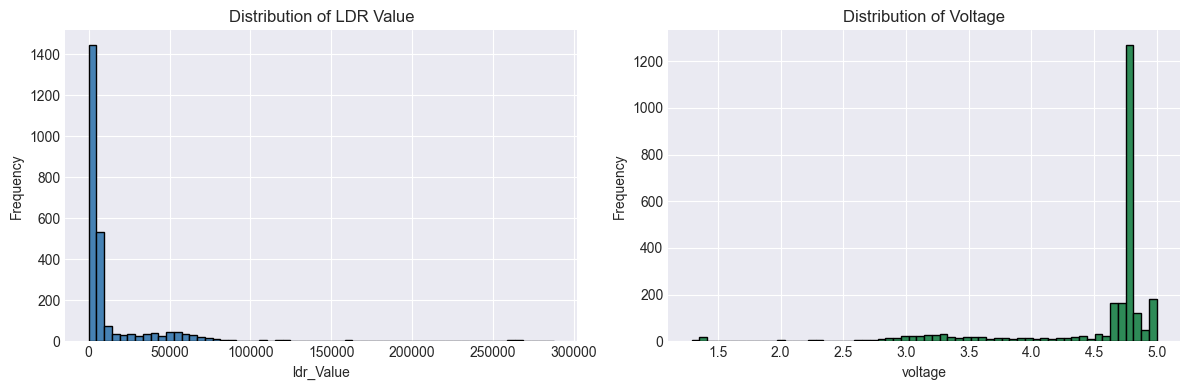

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["ldr_Value"], bins=60, color="steelblue", edgecolor="black")
axes[0].set_title("Distribution of LDR Value")
axes[0].set_xlabel("ldr_Value")
axes[0].set_ylabel("Frequency")

axes[1].hist(df["voltage"], bins=60, color="seagreen", edgecolor="black")
axes[1].set_title("Distribution of Voltage")
axes[1].set_xlabel("voltage")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

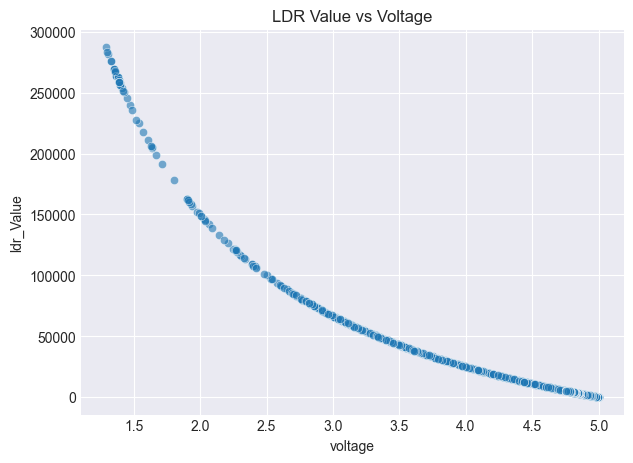

Correlation between ldr_Value and voltage: -0.9264


In [33]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="voltage", y="ldr_Value", alpha=0.6)
plt.title("LDR Value vs Voltage")
plt.show()

print("Correlation between ldr_Value and voltage:", round(df["ldr_Value"].corr(df["voltage"]), 4))

### What we achieved — EDA

- The dataset has **2599** readings; almost all rows are valid.
- The 17 rows with `ldr_Value == 0` are boundary readings and are excluded from model training.
- LDR value and voltage show a strong relationship, which means `voltage` is a good input feature for predicting the LDR value.

## 4. Regression Task — Predict `ldr_Value` from `voltage`

In [34]:
reg_df = df[df["ldr_Value"] > 0].copy()

X_reg = reg_df[["voltage"]].values
y_reg = reg_df["ldr_Value"].values

# Keep samples in time order so nearby repeated readings do not leak across splits.
split_index = int(len(reg_df) * 0.8)
X_train, X_test = X_reg[:split_index], X_reg[split_index:]
y_train, y_test = y_reg[:split_index], y_reg[split_index:]

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 2065
Testing samples: 517


In [35]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin_reg = lin_reg.predict(X_test)

lin_rmse = float(np.sqrt(mean_squared_error(y_test, y_pred_lin_reg)))
lin_r2 = r2_score(y_test, y_pred_lin_reg)

print(f"Linear Regression -> RMSE: {lin_rmse:.2f}, R2: {lin_r2:.4f}")

Linear Regression -> RMSE: 3399.67, R2: -57.8081


In [36]:
rf_reg = RandomForestRegressor(n_estimators=200, random_state=42)
rf_reg.fit(X_train, y_train)
y_pred_rf_reg = rf_reg.predict(X_test)

rf_rmse = float(np.sqrt(mean_squared_error(y_test, y_pred_rf_reg)))
rf_r2 = r2_score(y_test, y_pred_rf_reg)

print(f"Random Forest Regressor -> RMSE: {rf_rmse:.2f}, R2: {rf_r2:.4f}")

Random Forest Regressor -> RMSE: 61.16, R2: 0.9810


In [37]:
gbr = GradientBoostingRegressor(n_estimators=100, random_state=42)
gbr.fit(X_train, y_train)
y_pred_gbr = gbr.predict(X_test)

gbr_rmse = float(np.sqrt(mean_squared_error(y_test, y_pred_gbr)))
gbr_r2 = r2_score(y_test, y_pred_gbr)

print(f"Gradient Boosting Regressor -> RMSE: {gbr_rmse:.2f}, R2: {gbr_r2:.4f}")

Gradient Boosting Regressor -> RMSE: 62.61, R2: 0.9801


In [38]:
regression_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regressor", "Gradient Boosting Regressor"],
    "RMSE": [lin_rmse, rf_rmse, gbr_rmse],
    "R2": [lin_r2, rf_r2, gbr_r2],
})
regression_results

,Model,RMSE,R2
0,Linear Regression,3399.670144,-57.808073
1,Random Forest Regressor,61.157486,0.980969
2,Gradient Boosting Regressor,62.613047,0.980052


In [39]:
best_regression_model = regression_results.loc[regression_results["RMSE"].idxmin(), "Model"]
best_regression_model


'Random Forest Regressor'

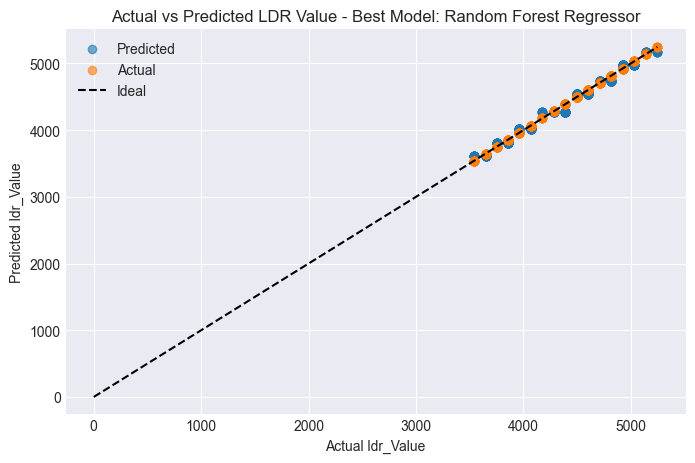

In [40]:
best_regression_model = regression_results.loc[regression_results["RMSE"].idxmin(), "Model"]
best_reg_model = {"Linear Regression": lin_reg, "Random Forest Regressor": rf_reg, "Gradient Boosting Regressor": gbr}[best_regression_model]
y_pred_best_reg = best_reg_model.predict(X_test)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_best_reg, alpha=0.6, label="Predicted")
plt.scatter(y_test, y_test, alpha=0.6, label="Actual")
plt.plot([0, y_test.max()], [0, y_test.max()], "k--", label="Ideal")
plt.xlabel("Actual ldr_Value")
plt.ylabel("Predicted ldr_Value")
plt.title(f"Actual vs Predicted LDR Value - Best Model: {best_regression_model}")
plt.legend()
plt.show()


In [41]:
import pickle

# Refit the selected model on all valid readings for the deployed artifact.
best_reg_model.fit(X_reg, y_reg)
with open(Path("best_model.pkl"), "wb") as f:
    pickle.dump(best_reg_model, f)

print("Best regression model saved to best_model.pkl:", best_regression_model)


Best regression model saved to best_model.pkl: Random Forest Regressor


### What we achieved ? Regression

- Valid rows were split by time: the first 80% for training, the final 20% for evaluation.
- Linear Regression holdout RMSE: **3,399.67 ?** (R? = **-57.8081**).
- Random Forest Regressor holdout RMSE: **61.16 ?** (R? = **0.98097**).
- Gradient Boosting Regressor holdout RMSE: **62.61 ?** (R? = **0.98005**).
- The Random Forest Regressor had the lowest RMSE and is refit on all valid readings before export.


## 5. Classification Task ? High Brightness, Brightness, and Dark from resistance


In [42]:
CLASS_LABELS = ["High Brightness", "Brightness", "Dark"]
valid_rows = df["ldr_Value"] > 0
valid_resistance = df.loc[valid_rows, "ldr_Value"]
RESISTANCE_CUTOFFS = np.quantile(valid_resistance, [1 / 3, 2 / 3])
HIGH_BRIGHTNESS_MAX, BRIGHTNESS_MAX = RESISTANCE_CUTOFFS

df["brightness"] = pd.Series(pd.NA, index=df.index, dtype="string")
df.loc[valid_rows, "brightness"] = np.select(
    [
        df.loc[valid_rows, "ldr_Value"] <= HIGH_BRIGHTNESS_MAX,
        df.loc[valid_rows, "ldr_Value"] <= BRIGHTNESS_MAX,
    ],
    CLASS_LABELS[:2],
    default=CLASS_LABELS[2],
)
valid_df_clf = df.loc[valid_rows].copy()

print(f"High Brightness: resistance <= {HIGH_BRIGHTNESS_MAX:.2f} ohms")
print(f"Brightness: {HIGH_BRIGHTNESS_MAX:.2f} to {BRIGHTNESS_MAX:.2f} ohms")
print(f"Dark: resistance > {BRIGHTNESS_MAX:.2f} ohms")
print("Category counts:\n", valid_df_clf["brightness"].value_counts())

# Train the classifier on out-of-fold resistance estimates so its input matches
# the regression model's predicted resistance feature used by the API.
X_clf = cross_val_predict(
    best_reg_model,
    X_reg,
    y_reg,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
).reshape(-1, 1)
y_clf = valid_df_clf["brightness"].to_numpy()


High Brightness: resistance <= 4281.34 ohms
Brightness: 4281.34 to 6230.53 ohms
Dark: resistance > 6230.53 ohms
Category counts:
 brightness
High Brightness    965
Dark               855
Brightness         762
Name: count, dtype: Int64


In [43]:
df.sample(10)

,ldr_Value,voltage,time,brightness
430,1588.88,4.92,40760.0,High Brightness
1328,4175.15,4.79,131877.0,High Brightness
701,12541.25,4.44,68257.0,Dark
788,6562.50,4.69,77082.0,Dark
2572,5030.80,4.76,258121.0,Brightness
347,97.85,4.99,32344.0,High Brightness
406,2197.80,4.89,38325.0,High Brightness
2209,3542.51,4.82,221286.0,High Brightness
494,15855.04,4.31,47251.0,Dark
1301,5030.80,4.76,129137.0,Brightness


In [17]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

log_clf = LogisticRegression(max_iter=1000, random_state=42)
log_clf.fit(X_train_c, y_train_c)
y_pred_log = log_clf.predict(X_test_c)

log_acc = accuracy_score(y_test_c, y_pred_log)
print(f"Logistic Regression -> Accuracy: {log_acc:.4f}")
print(classification_report(y_test_c, y_pred_log, labels=CLASS_LABELS, target_names=CLASS_LABELS, zero_division=0))


Logistic Regression -> Accuracy: 0.9458
                 precision    recall  f1-score   support

High Brightness       0.89      1.00      0.94       193
     Brightness       1.00      0.82      0.90       153
           Dark       0.98      1.00      0.99       171

       accuracy                           0.95       517
      macro avg       0.96      0.94      0.94       517
   weighted avg       0.95      0.95      0.94       517



In [18]:
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42)
rf_clf.fit(X_train_c, y_train_c)
y_pred_rf_clf = rf_clf.predict(X_test_c)

rf_acc = accuracy_score(y_test_c, y_pred_rf_clf)
print(f"Random Forest Classifier -> Accuracy: {rf_acc:.4f}")
print(confusion_matrix(y_test_c, y_pred_rf_clf, labels=CLASS_LABELS))


Random Forest Classifier -> Accuracy: 0.9458
[[193   0   0]
 [ 25 125   3]
 [  0   0 171]]


In [19]:
classification_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest Classifier"],
    "Accuracy": [log_acc, rf_acc],
})
classification_results

,Model,Accuracy
0,Logistic Regression,0.945841
1,Random Forest Classifier,0.945841


In [20]:
best_classification_model = "Random Forest Classifier" if rf_acc >= log_acc else "Logistic Regression"
best_classification_model


'Random Forest Classifier'

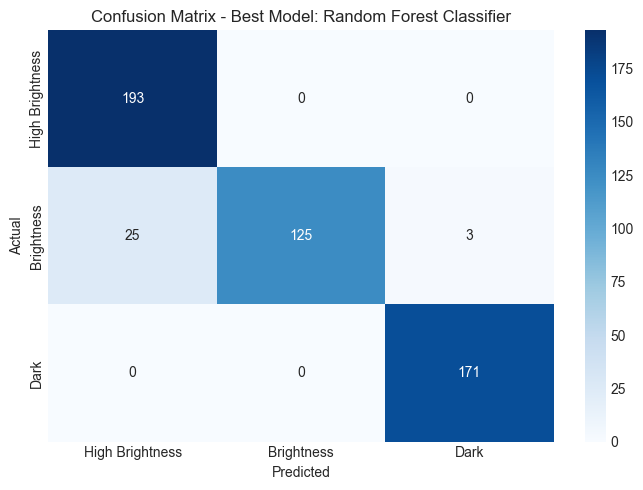

Brightness classifier saved to brightness_model.pkl: Random Forest Classifier


In [21]:
best_clf_model = {
    "Logistic Regression": log_clf,
    "Random Forest Classifier": rf_clf,
}[best_classification_model]
y_pred_best_clf = best_clf_model.predict(X_test_c)

cm = confusion_matrix(y_test_c, y_pred_best_clf, labels=CLASS_LABELS)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - Best Model: {best_classification_model}")
plt.tight_layout()
plt.show()

# Refit the selected classifier on all out-of-fold resistance estimates and save
# it separately from the voltage-to-resistance regression model.
best_clf_model.fit(X_clf, y_clf)
with open(Path("brightness_model.pkl"), "wb") as model_file:
    pickle.dump(best_clf_model, model_file)
print("Brightness classifier saved to brightness_model.pkl:", best_classification_model)


### What we achieved ? Classification

- Added a `brightness` column for every valid LDR row using resistance terciles.
- **High Brightness:** resistance <= **4,281.34 ?**.
- **Brightness:** resistance > 4,281.34 ? and <= **6,230.53 ?**.
- **Dark:** resistance > 6,230.53 ?.
- The classifier receives out-of-fold resistance estimates from the regression model, matching the feature it receives in the API.
- Random Forest Classifier accuracy on a stratified holdout: **0.9458**.
- The final classifier is refit on all rows and saved as `brightness_model.pkl`.

The categories are defined from the current dataset's resistance distribution. They are not calibrated lux ranges.


## 6. Final Conclusion

- **Regression model:** Random Forest Regressor predicts LDR resistance from voltage. It is saved as `best_model.pkl`.
- **Classification model:** Random Forest Classifier predicts `High Brightness`, `Brightness`, or `Dark` from the regression model's predicted resistance. It is saved separately as `brightness_model.pkl`.
- At inference time, the backend runs regression first, passes the estimated resistance to the classifier, and returns both resistance and category.

The resistance categories use the current dataset's one-third and two-thirds quantiles. They provide relative brightness levels and are not calibrated against a lux meter.
